# 01 — Data collection & exploration

**Owners:** game-side tables: minhnguyen1210 · player-side tables: CaoThien1402

Spec sections 3.1 (data collection) and 3.2 (data exploration).

**Inputs:** TODO: files this notebook reads (`data/raw/<platform>/<table>.csv` or `data/processed/...`).

**Outputs:** TODO: files this notebook writes to `data/processed/`, and figures saved to `reports/figures/`.

In [1]:
import sys
from pathlib import Path

# Make the repo root importable (works from the repo root or from notebooks/)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import RAW_DIR, PROCESSED_DIR, FIG_DIR, PLATFORMS, TABLES, RANDOM_STATE
from src.data_loading import load_table, load_all
from src.utils import report_rows

pd.set_option("display.max_columns", 50)
FIG_DIR.mkdir(parents=True, exist_ok=True)

## 1 Data collection

This section documents what the data describes, where it comes from, under which license it is released and how it was
collected. Facts about the source come from the dataset's Kaggle page and from the author's open-source collection
project, GameStatsHub (both accessed on 21 November 2026). Statements about the content of the files were checked against
the raw data; the code that measures them is in section 2.

### 1.1 Subject

The dataset describes three major video game platforms, **Steam** (PC), **PlayStation** and **Xbox**, from two
complementary sides:

- **Games (supply side):** the game catalogue of each platform (title, developers, publishers, genres, supported
  languages, release date), the achievements or trophies defined for each game, and store prices recorded on several
  dates in five currencies (USD, EUR, GBP, JPY, RUB).
- **Players (demand side):** public player profiles, the games in each player's library and, for a subset of players,
  a time-stamped history of the achievements they unlocked. For Steam only, it also contains user reviews (text,
  "helpful" and "funny" votes, awards) and friend lists.

**Real-world context.** Achievements (Steam, Xbox) and trophies (PlayStation) are in-game milestones that the platform
records with a timestamp when a player reaches them. A player's unlock history is therefore a behavioural trace of which
games they play, when, and how far they progress, observed directly rather than self-reported in a survey. Store prices
recorded repeatedly show how publishers price and discount their games over time, including during Steam's seasonal
sales.

**Scale.** 21 CSV tables (six per platform plus three Steam-only tables) with about 56.4 million rows in total; the
largest table, `history`, holds 45.5 million unlock events (row counts in section 2.1). Each table is narrow (1 to 8
columns), but the tables share keys (`gameid`, `achievementid`, `playerid`) and together hold 41 distinct table columns,
so the analysis combines tables (section 2.3) rather than relying on a single wide table.

### 1.2 Source

| Item | Detail |
| --- | --- |
| Platform | Kaggle |
| Title | *Gaming Profiles 2025 (Steam, PlayStation, Xbox)*, subtitled "Comparison of User Behavior Across Different Gaming Platforms" |
| URL | <https://www.kaggle.com/datasets/artyomkruglov/gaming-profiles-2025-steam-playstation-xbox> |
| Author | Artyom Kruglov (Kaggle user `artyomkruglov`) |
| Collection code | GameStatsHub, <https://github.com/Smipe-a/gamestatshub>. The Kaggle description links to this repository and its README links back to the Kaggle page. |
| Publication date | 25 February 2025: version 1, "Initial release", still the only version on 21 November 2026 |
| Version used | Version 1, pinned in `scripts/download_data.sh` so that every run analyses the same files |
| Format and size | 21 CSV files, 4,034,016,221 bytes (about 4.0 GB); checked in the cell below |
| Original sources | [Steam Web API](https://steamcommunity.com/dev) and the [Steam Store](https://store.steampowered.com); [Exophase](https://www.exophase.com) (PlayStation and Xbox games, leaderboards and player histories); [TrueTrophies](https://www.truetrophies.com) and [TrueAchievements](https://www.trueachievements.com) (missing PlayStation and Xbox game details); [PSPrices](https://psprices.com) (PlayStation and Xbox prices) |

The Kaggle description advertises "~60GB" of data. This figure refers to the author's full PostgreSQL database, which
GameStatsHub distributes as a 3.8 GB SQL dump that requires at least 60 GB of free disk space to restore. The Kaggle
release is a 4.0 GB CSV
export of the database tables.

In [2]:
# Inventory of the raw files: all 21 tables of version 1 must be present.
# Kaggle reports 4,034,016,221 bytes for version 1 of the dataset.
files = [(platform, name, RAW_DIR / platform / f"{name}.csv")
         for platform in PLATFORMS for name in TABLES[platform]]
inventory = pd.DataFrame(
    [{"platform": platform, "table": name, "size_MB": path.stat().st_size / 1e6}
     for platform, name, path in files]
)
total_bytes = sum(path.stat().st_size for _, _, path in files)
print(f"{len(files)} files, {total_bytes:,} bytes in total")
inventory.pivot(index="table", columns="platform", values="size_MB").round(1)

21 files, 4,034,016,221 bytes in total


platform,playstation,steam,xbox
table,,,
achievements,70.1,144.8,29.0
friends,NaN,658.1,NaN
games,3.4,17.1,1.3
history,799.1,647.6,633.3
players,10.7,18.4,5.4
prices,2.3,183.9,0.8
private_steamids,NaN,4.3,NaN
purchased_games,74.4,91.7,86.5
reviews,NaN,551.6,NaN


### 1.3 License

The dataset is released under **CC0 1.0 Universal (Public Domain Dedication)** on Kaggle, and the GameStatsHub
repository carries the same license. Under CC0 the author waives copyright and related rights, so the data may be copied,
modified and redistributed, including for commercial purposes, without asking for permission. Attribution is not legally
required; we nevertheless cite the author and the repository, because academic practice and the course brief require
traceable sources.

Two restrictions still apply to how we use the data:

- **Rights in the original content.** CC0 covers the author's compilation. The underlying material (game descriptions,
  achievement texts, review texts) originates from Valve, Sony, Microsoft and the websites listed in section 1.2, whose
  terms of use govern the original content. We use it only for this non-commercial course project.
- **Personal data.** The tables contain real player identifiers (Steam IDs, PlayStation and Xbox nicknames) and
  user-written review text. The profiles were public when collected, but we still treat these fields as personal data:
  we report aggregate results only and never single out, name or try to re-identify an individual player.

### 1.4 Collection method

**How the data was collected.** The data was gathered by automated web scraping and public APIs. GameStatsHub runs a set
of Python scripts for each platform, orchestrated with Apache Airflow, and stores the results in a PostgreSQL database
(Figure 1); the Kaggle files are a CSV export of that database. The scripts in the repository show how each table was
filled:

| Tables | Source | Procedure |
| --- | --- | --- |
| Steam `players`, `friends` | Steam Web API (`GetPlayerSummaries`, `GetFriendList`) | Snowball sampling: starting from seed accounts taken from different sections and game categories of Steam, the crawler follows friend lists to new accounts. `country` is the optional location shown on the profile; `created` is the account creation time. |
| Steam `purchased_games`, `history` | Steam Web API (`GetOwnedGames`, `GetPlayerAchievements`) | Players are processed in random order. For each player, the owned games and the unlocked achievements (with timestamps) of games already in the database are stored. Private profiles get an empty library. |
| Steam `reviews`, `private_steamids` | Each player's public review pages | Reviews of games in the database are scraped, with the vote counts parsed from the review header. Players for whom no review can be collected are stored in `private_steamids`. |
| Steam `games`, `achievements` | Steam Web API (`GetAppList`, `GetSchemaForGame`) and the US Steam Store (`appdetails`) | Catalogue of all Steam apps with their store details and achievement lists. |
| PlayStation and Xbox `players` | Exophase leaderboards | All leaderboard pages are scraped; player id and nickname come from each profile page. PlayStation `country` is read from the flag shown on the leaderboard; Xbox players have no country. |
| PlayStation and Xbox `games`, `achievements` | Exophase game archive; TrueTrophies (PlayStation) and TrueAchievements (Xbox) | Games and their trophies (PlayStation `rarity` grade) or achievements (Xbox `points`). Missing developers, publishers, genres and release dates are filled from TrueTrophies or TrueAchievements by fuzzy title matching (Levenshtein distance). |
| PlayStation and Xbox `purchased_games`, `history` | Exophase API | Players are processed in random order; the games on each Exophase profile and their unlock timestamps are stored. |
| `prices` (all platforms) | Steam Store API; PSPrices for PlayStation and Xbox | On each collection day, the current price is recorded in five store regions (US, DE, GB, JP, RU). For Steam this is the store's `final` price, i.e. the price after any active discount. Console prices are found by searching PSPrices for the game title and platform and keeping the closest title match. |

![GameStatsHub data pipeline](../reports/figures/collect_gamestatshub_pipeline.png)

*Figure 1. GameStatsHub data pipeline. Source: [Smipe-a/gamestatshub](https://github.com/Smipe-a/gamestatshub),
`img/data_pipeline.png` (CC0).*

**Structure.** Each platform is stored as its own schema with the same core tables. Figure 2 shows the Steam schema. The
PlayStation and Xbox schemas contain the same six core tables without `reviews`, `friends` and `private_steamids`, and
differ only in a few columns: `games.platform` (PS4, PS5, PS3, PS Vita) and `achievements.rarity` (Bronze, Silver, Gold,
Platinum) on PlayStation, `achievements.points` on Xbox, and `players.nickname` on both consoles (plus `players.country`
on PlayStation) instead of Steam's `country` and `created`. The primary keys define what one row is: a game (`gameid`),
an achievement (`achievementid`), a player (`playerid`), one unlock (`playerid`, `achievementid`) and one price
observation (`gameid`, `date_acquired`).

![Steam schema of the GameStatsHub database](../reports/figures/collect_gamestatshub_steam_erd.png)

*Figure 2. Entity-relationship diagram of the Steam tables. Source:
[Smipe-a/gamestatshub](https://github.com/Smipe-a/gamestatshub), `img/steam_erd.png` (CC0).*

**Population.** The data is not a random sample of gamers.

| | Steam | PlayStation | Xbox |
| --- | --- | --- | --- |
| How players enter the data | snowball sampling over friend lists | Exophase leaderboard (ranked by achievement points) | Exophase leaderboard (ranked by achievement points) |
| Player profiles (`players`) | 424,683 | 356,600 | 274,450 |
| Players with an unlock history (`history`) | 4,838 | 5,000 | 4,984 |

**Period.** The GameStatsHub repository was created on 2 October 2024 and the last price snapshot is dated
25 February 2025, so the collection took place roughly between these two dates. The events it records are much older.
The author states a temporal coverage from 12 September 2008 to 12 January 2025; in the files, unlock timestamps run
from 12 September 2008 to 29 December 2024,
reviews from 15 October 2010 to 9 January 2025 and Steam account creation dates from 11 September 2003 to 7 January 2025.
Prices cover 45 dates, one every two days, for Steam (28 November 2024 to 24 February 2025), but only three dates for
PlayStation and two for Xbox (22 to 25 February 2025). Section 2.4 measures these ranges.

**Known limitations and biases.**

1. **Selection bias.** Console players come from leaderboards that rank players by achievement points, so they are
   dedicated achievement hunters. Steam players are reached through friend lists, which favours socially connected users
   with public profiles. Findings about behaviour describe these groups, not the average player.
2. **Small behavioural subsample.** Unlock histories exist for only about 5,000 players per platform, 1 to 2 % of the
   collected profiles.
3. **Public data only.** Private profiles leave gaps: 55,607 of 102,548 Steam libraries (54.2 %) are empty, and 41.9 %
   of Steam players have no `country` (section 2.1). These gaps are unlikely to be random.
4. **Parsing artefacts in `reviews`.** The vote counts are read with a pattern that only matches "N people found this
   review helpful". Steam writes a single vote as "1 person", so one vote is stored as 0: no review has `helpful = 1`,
   whereas 98,268 have `helpful = 2`. Counts written with a thousands separator keep only their last three digits
   ("1,234" becomes 234 and "1,000" becomes 0), so `helpful` never exceeds 999. `funny` is parsed in the same way.
   In addition, `posted` holds the date of the last edit when a review was edited.
5. **Misleading table names.** `private_steamids` lists every Steam player for whom no review could be collected,
   whether the profile is private or the player never wrote a review: the 196,698 reviewers and the 227,963 players in
   `private_steamids` together make up all but 22 of the 424,683 Steam players. PlayStation and Xbox `purchased_games`
   hold the games shown on an Exophase profile, which are games played, not necessarily purchased.
6. **Matching by title.** Console prices (PSPrices) and missing console game details (TrueTrophies, TrueAchievements)
   are matched to games by title, which can attach the data to the wrong game or edition.
7. **Incomplete export.** In the author's schema, `prices` and `achievements` refer to `games` through a foreign key, yet
   7,570 PlayStation and 830 Xbox game ids that appear in `achievements` and `prices` have no row in `games.csv`; on
   Steam, 217 priced games and 77 games with achievements are missing as well (section 2.3).
8. **Snapshots and time zones.** Profiles, libraries and friend lists are a single snapshot taken between late 2024 and
   early 2025, not the state at the time of past events. Unlock times were converted from UNIX timestamps with the local
   time zone of the collecting machine, which is not documented, so clock times may be shifted by a constant offset.
9. **No updates.** The dataset is described as "Regularly Updated", but version 1 is the only release, so the data ends
   in early 2025.

### 1.5 Motivation

Video games are a topic both of us enjoy, and one of us regularly follows news about the major gaming platforms. That
coverage made us curious about what lies behind the headlines: how the market for games actually works, and how other
players behave once a game is in their library. This dataset lets us study both questions with real data instead of
anecdotes.

Four features make it a good fit for our project:

- **Three platforms, one table structure.** Steam, PlayStation and Xbox share the same core tables, so the platforms
  can be compared directly rather than through separate, incompatible sources.
- **Observed behaviour over 16 years.** 45.5 million time-stamped achievement unlocks (2008 to 2024) record what players
  actually did, not what they say they did in a survey.
- **Prices during real sales.** Steam prices recorded every two days from November 2024 to February 2025 cover two major
  sales, at whose peaks about 60 % of the games priced throughout the period were discounted.
- **Real, imperfect data.** Four gigabytes of CSV files in 21 linked tables, with missing values and collection
  artefacts (section 1.4), call for the loading, cleaning and joining skills this course teaches. The dataset is also
  public, released under CC0, traceable to its collection code and still little analysed: Kaggle lists only nine public
  notebooks for it (November 2026).

Our findings can inform several stakeholders: **players** deciding when and on which platform to buy a game;
**independent developers** setting prices and designing achievements that keep players engaged; **platform operators**
planning sales and engagement features; and **researchers** studying player behaviour across gaming ecosystems.

## 2 Data exploration

Go deep on the columns relevant to our questions; summarise the rest briefly instead of one chart per column.

Each subsection has one code cell per table group, so the two members can work in parallel:
**game side** (`games`, `achievements`, `prices`) and **player side** (`players`, `history`, `purchased_games`,
`reviews`, `friends`, `private_steamids`).

### 2.1 Loading strategy

**Player-side tables** (`players`, `history`, `purchased_games`, `reviews`, `friends`, `private_steamids`; owner: CaoThien1402).
The game-side tables (`games`, `achievements`, `prices`) are covered by minhnguyen1210 in the first code cell of each subsection.

All player-side tables fit in memory (the largest, PlayStation `history`, needs 1.6 GB), so nothing is read in chunks
for now. The settings live in `PLAYER_READ_ARGS` in `src/data_loading.py` and are used through `load_player_table`.

| Decision | Tables | Why |
| --- | --- | --- |
| `int64` for Steam ids, `int32` for PlayStation and Xbox ids | all | Steam ids are about 7.6e16 and overflow `int32`; the other platforms use ids below 2^31 |
| `parse_dates` | `history.date_acquired`, `players.created`, `reviews.posted` | dates are read as text otherwise, so time arithmetic and resampling need a conversion later |
| `country` as `category` | Steam, PlayStation `players` | few distinct values repeated over hundreds of thousands of rows: the Steam table drops from 56 MB to 8 MB |
| `achievementid` as `string` | `history` | the id is text (`403640_ACH_1`); `history` uses 42-47% less memory than with the defaults (measured on 200,000 rows) |
| `usecols` without `review` | `reviews` | the review text is about 94% of the memory (715 MB with the text, 43 MB without it); Q4 reads the text only if it builds text features |
| `keep_default_na=False, na_values=[""]` | `players` | only an empty cell is missing; with the default setting pandas also turns the nickname `null` (one Xbox player) into `NaN` |
| one table at a time, then `del` | `history`, `reviews`, `friends` | keeps memory below about 2 GB; reading `history` takes 20-33 s per platform |

**Columns that hold a list as text.** `library` (`purchased_games`) and `friends` (`friends`) store lists such as
`"[60, 1670]"`. Parsing about 65 million ids with `ast.literal_eval` would be slow, so the tables are kept as text and
`count_list_items` counts the items (number of commas plus one). `parse_id_list` turns a single cell into a Python list
when the ids themselves are needed (for example for `explode`).

**Empty list cells are real missing data, not an empty list.** In the raw file, 55,607 of 102,548 Steam libraries
(54.2%) and 85,222 of 424,683 friend lists (20.1%) are empty cells; the text `"[]"` never appears. PlayStation and Xbox
libraries have no empty cell. Most likely these are private profiles, but the dataset does not say so; we treat them as
unknown, not as "owns no game". Any statement about library size or friends is therefore limited to the players who
made them public.

**Other things checked while loading**
- `reviews` contains text cells that span several lines. The default C parser of pandas reads them correctly (1,204,534
  rows, the same number as the author's description), so we do not use the `pyarrow` engine for this table.
- Steam `players.country` has 177,868 empty cells (41.9%); PlayStation `players` has a `country` column, Xbox has none.
  See section 2.7.
- `private_steamids` has no duplicated id (227,963 rows).

The two tables below show the result for every player-side table: size on disk, rows, memory after loading, saving
from the dtype settings on a 200,000-row sample, and read time. `reviews` is shown with its text (see above).

#### Game-side tables (`games`, `achievements`, `prices`; owner: minhnguyen1210)

All nine game-side tables fit in memory and load in under two seconds each (the largest in memory is Steam
`achievements`, 1.9 million rows and about 460 MB), so none of them is read in chunks. The settings live in
`GAME_READ_ARGS` in `src/data_loading.py` and are used through `load_game_table`. The cells below provide the evidence
for each decision.

| Decision | Tables | Why |
| --- | --- | --- |
| `gameid` as `int32` | all | the largest id is 3,441,890, far below the `int32` limit of 2,147,483,647; the key takes half the memory of `int64` |
| `parse_dates` | `games.release_date`, `prices.date_acquired` | dates become `datetime64`, ready for date arithmetic; every value parses. On Steam `prices` this alone saves about 55 % of the memory, because 45 repeated date strings are replaced by 8-byte timestamps |
| `achievementid` as `string` | `achievements` | same dtype as `history.achievementid` on the player side, so the two tables join without conversion |
| `keep_default_na=False, na_values=[""]` | `achievements` | with the defaults, pandas turns real titles and descriptions such as "NA", "NULL" and "null" into `NaN` (14 texts on Steam, 4 on PlayStation, 1 on Xbox); only an empty cell should count as missing |
| `rarity` as an ordered category (Bronze < Silver < Gold < Platinum) | PlayStation `achievements` | four values repeated 846,563 times; the order makes sorting and plots follow the real trophy hierarchy instead of the alphabet |
| `platform` as `category` | PlayStation `games` | four values (PS3, PS4, PS5, PS Vita) |
| `points` as nullable `Int16` | Xbox `achievements` | whole numbers from 0 to 1,000 with 878 missing values; `Int16` keeps them as integers despite the gaps |
| prices kept as `float64` | `prices` | `float32` would store 4.99 as 4.9899998, which makes price comparisons (has the price changed?) unreliable |
| default C parser, not `pyarrow` | all | the `pyarrow` engine fails on PlayStation `achievements`, where 8,431 descriptions contain line breaks inside quoted cells |
| list columns parsed with `ast.literal_eval` (`parse_list_column`) | `games`: `developers`, `publishers`, `genres`, `supported_languages` | some names contain a comma ("TALESSHOP Co., Ltd."), so counting commas, as `count_list_items` does for id lists, is wrong for 2,061 Steam developer lists and 2,159 publisher lists |

Text columns (titles, descriptions and the list columns) stay as `object`. They hold most of the memory of `games` and
`achievements` (the dtype settings save only 2 % on Steam `achievements`), and later notebooks will read only the
columns they need with `usecols`. Missing list cells stay `NaN` rather than becoming an empty list: no list column
contains `"[]"`, so a missing cell means "unknown", the same convention as for the player-side list columns above.

In [3]:
# Game side: games, achievements, prices (owner: minhnguyen1210)
import gc
import time

from src.data_loading import GAME_SIDE_TABLES, load_game_table, table_path

SAMPLE_ROWS = 200_000  # same sample size as the player-side comparison below

records = []
for platform, name in GAME_SIDE_TABLES:
    # Memory saved by GAME_READ_ARGS: the same first rows read with pandas defaults and with our settings
    default_mb = load_table(platform, name, nrows=SAMPLE_ROWS).memory_usage(deep=True).sum() / 1e6
    tuned_mb = load_game_table(platform, name, nrows=SAMPLE_ROWS).memory_usage(deep=True).sum() / 1e6

    start = time.perf_counter()
    df = load_game_table(platform, name)  # the full table, one at a time
    seconds = time.perf_counter() - start
    records.append({
        "platform": platform, "table": name,
        "file_MB": round(table_path(platform, name).stat().st_size / 1e6),
        "rows": len(df), "columns": df.shape[1],
        "memory_MB": round(df.memory_usage(deep=True).sum() / 1e6),
        "sample_saving_%": round(100 * (1 - tuned_mb / default_mb)),
        "seconds": round(seconds, 1),
        "max_gameid": int(df["gameid"].max()),  # must stay below 2,147,483,647 to fit int32
        "unparsed_dates": int(df.select_dtypes("datetime").isna().sum().sum()),
    })
    del df
    gc.collect()

game_loading_summary = pd.DataFrame(records)
game_loading_summary

,platform,table,file_MB,rows,columns,memory_MB,sample_saving_%,seconds,max_gameid,unparsed_dates
0,steam,games,17,98248,7,43,12,0.2,3441890,0
1,playstation,games,3,23151,8,9,23,0.0,766555,0
2,xbox,games,1,10489,7,4,14,0.0,766495,0
3,steam,achievements,145,1939027,4,462,2,1.8,3425420,0
4,playstation,achievements,70,846563,5,207,22,0.8,767036,0
5,xbox,achievements,29,351111,5,87,4,0.5,767046,0
6,steam,prices,184,4414273,7,230,55,1.7,3441890,0
7,playstation,prices,2,62816,7,3,55,0.0,767036,0
8,xbox,prices,1,22638,7,1,55,0.0,767046,0


In [4]:
# Achievements: which parser engine works, and which texts pandas would silently turn into NaN
engine_checks = []
for platform in PLATFORMS:
    achievements = load_game_table(platform, "achievements")
    texts = achievements[["title", "description"]]

    # The pyarrow engine is faster, but it cannot read quoted cells that contain line breaks
    try:
        n_rows = len(pd.read_csv(table_path(platform, "achievements"), engine="pyarrow"))
        pyarrow_result = "reads all rows" if n_rows == len(achievements) else f"reads {n_rows:,} rows instead of {len(achievements):,}"
    except Exception as error:
        pyarrow_result = f"fails ({type(error).__name__})"

    # With pandas defaults, text such as "NA" or "NULL" becomes NaN although it is a real achievement title
    default_texts = load_table(platform, "achievements", usecols=["title", "description"])
    lost = default_texts.isna() & texts.notna()
    engine_checks.append({
        "platform": platform,
        "descriptions_with_line_breaks": int(texts["description"].str.contains("\n", na=False).sum()),
        "pyarrow_engine": pyarrow_result,
        "texts_lost_with_defaults": int(lost.sum().sum()),
        "examples": sorted(set(texts["title"][lost["title"]]) | set(texts["description"][lost["description"]])),
    })
    del achievements, texts, default_texts
pd.DataFrame(engine_checks)

,platform,descriptions_with_line_breaks,pyarrow_engine,texts_lost_with_defaults,examples
0,steam,197,reads all rows,14,"[NA, NULL, null]"
1,playstation,8431,fails (ParserError),4,[NULL]
2,xbox,717,reads all rows,1,[NULL]


In [5]:
# List columns of the games tables: parse them as Python lists rather than counting commas
from src.data_loading import GAME_LIST_COLUMNS, count_list_items, parse_list_column

list_checks = []
for platform in PLATFORMS:
    games = load_game_table(platform, "games")
    for column in GAME_LIST_COLUMNS:
        parsed = parse_list_column(games[column])  # NaN stays NaN: the value is unknown, not an empty list
        present = parsed.notna()
        comma_inside = parsed[present].map(lambda items: any("," in item for item in items))
        list_checks.append({
            "platform": platform, "column": column,
            "non_missing": int(present.sum()),
            "empty_lists": int((parsed[present].map(len) == 0).sum()),
            "names_with_a_comma": int(comma_inside.sum()),
            "wrong_comma_counts": int((count_list_items(games[column])[present] != parsed[present].map(len)).sum()),
        })
pd.DataFrame(list_checks)

,platform,column,non_missing,empty_lists,names_with_a_comma,wrong_comma_counts
0,steam,developers,92689,0,2061,2061
1,steam,publishers,92307,0,2159,2159
2,steam,genres,92699,0,0,0
3,steam,supported_languages,92742,0,0,0
4,playstation,developers,23134,0,17,17
5,playstation,publishers,23140,0,12,12
6,playstation,genres,23009,0,0,0
7,playstation,supported_languages,10614,0,0,0
8,xbox,developers,9913,0,12,12
9,xbox,publishers,9944,0,4,4


In [6]:
# Example: a developer name with a comma is split in two when items are counted by commas
example = load_game_table("steam", "games", usecols=["gameid", "title", "developers"], parse_dates=None)
example = example[example["developers"].str.contains("Co., Ltd.", regex=False, na=False)].head(1)
example.assign(
    items_by_comma_count=count_list_items(example["developers"]),
    items_parsed=parse_list_column(example["developers"]).map(len),
)

,gameid,title,developers,items_by_comma_count,items_parsed
161,1429670,Dungeon Lord,"['TALESSHOP Co., Ltd.']",2,1


In [7]:
# Player side: players, history, purchased_games, reviews, friends, private_steamids (owner: CaoThien1402)
import gc
import time

from src.data_loading import PLAYER_SIDE_TABLES, count_list_items, load_player_table, table_path

SAMPLE_ROWS = 200_000  # sample used to compare memory with and without the settings in PLAYER_READ_ARGS

records = []
for platform, name in PLAYER_SIDE_TABLES:
    # memory saved by dtype / parse_dates: same first rows, default settings vs PLAYER_READ_ARGS
    default_mb = load_table(platform, name, nrows=SAMPLE_ROWS).memory_usage(deep=True).sum() / 1e6
    tuned_mb = load_player_table(platform, name, nrows=SAMPLE_ROWS).memory_usage(deep=True).sum() / 1e6

    start = time.perf_counter()
    df = load_player_table(platform, name)  # the full table, one at a time
    seconds = time.perf_counter() - start
    records.append({
        "platform": platform, "table": name,
        "file_MB": round(table_path(platform, name).stat().st_size / 1e6),
        "rows": len(df), "columns": df.shape[1],
        "memory_MB": round(df.memory_usage(deep=True).sum() / 1e6),
        "sample_saving_%": round(100 * (1 - tuned_mb / default_mb)),
        "seconds": round(seconds, 1),
    })
    del df
    gc.collect()

loading_summary = pd.DataFrame(records)
loading_summary

,platform,table,file_MB,rows,columns,memory_MB,sample_saving_%,seconds
0,steam,players,18,424683,3,8,86,0.3
1,playstation,players,11,356600,3,26,49,0.1
2,xbox,players,5,274450,2,20,5,0.1
3,steam,history,648,10693879,3,1001,42,7.9
4,playstation,history,799,19510083,3,1571,47,14.4
5,xbox,history,633,15275900,3,1239,47,11.3
6,steam,purchased_games,92,102548,2,95,0,0.5
7,playstation,purchased_games,74,46582,2,77,0,0.4
8,xbox,purchased_games,86,46466,2,89,0,0.5
9,steam,reviews,552,1204534,8,715,13,5.1


In [8]:
# Columns that store a list as text: how many cells are empty, and how many ids do they hold?
list_columns = [("steam", "purchased_games", "library"), ("playstation", "purchased_games", "library"),
                ("xbox", "purchased_games", "library"), ("steam", "friends", "friends")]
rows = []
for platform, name, column in list_columns:
    df = load_player_table(platform, name)
    items = count_list_items(df[column])
    rows.append({"platform": platform, "table": name, "rows": len(df),
                 "empty_cells": int(df[column].isna().sum()),
                 "empty_%": round(100 * df[column].isna().mean(), 1),
                 "ids_in_lists": int(items.sum()), "max_per_row": int(items.max())})
    del df
pd.DataFrame(rows)

,platform,table,rows,empty_cells,empty_%,ids_in_lists,max_per_row
0,steam,purchased_games,102548,55607,54.2,11258715,32463
1,playstation,purchased_games,46582,0,0.0,10893552,13540
2,xbox,purchased_games,46466,0,0.0,12667877,9018
3,steam,friends,424683,85222,20.1,30903334,2000


### 2.2 Overview & data dictionary

TODO, per table used:
- number of rows and columns; what one row represents;
- meaning and data type of each column; columns to drop or convert;
- duplicated or empty rows, and whether to remove them (justify).

| Table | Column | Type | Meaning | Action (keep / convert / drop) |
| --- | --- | --- | --- | --- |
| TODO | TODO | TODO | TODO | TODO |

In [9]:
# Game side: games, achievements, prices (owner: minhnguyen1210)
# Load the nine game-side tables once with the settings of section 2.1; sections 2.2-2.8 reuse them.
game = {(platform, name): load_game_table(platform, name) for platform, name in GAME_SIDE_TABLES}

KEYS = {"games": ["gameid"], "achievements": ["achievementid"], "prices": ["gameid", "date_acquired"]}
ONE_ROW = {"games": "a game", "achievements": "an achievement (trophy) of a game",
           "prices": "the price of a game on one date"}

overview = []
for (platform, name), df in game.items():
    overview.append({
        "platform": platform, "table": name, "one_row_is": ONE_ROW[name],
        "rows": len(df), "columns": df.shape[1],
        "duplicated_rows": int(df.duplicated().sum()),
        "duplicated_keys": int(df.duplicated(KEYS[name]).sum()),
        # rows whose non-key columns are all empty (for prices: no price in any currency)
        "rows_empty_except_key": int(df.drop(columns=KEYS[name]).isna().all(axis=1).sum()),
    })
pd.DataFrame(overview)

,platform,table,one_row_is,rows,columns,duplicated_rows,duplicated_keys,rows_empty_except_key
0,steam,games,a game,98248,7,0,0,0
1,playstation,games,a game,23151,8,0,0,0
2,xbox,games,a game,10489,7,0,0,0
3,steam,achievements,an achievement (trophy) of a game,1939027,4,0,0,0
4,playstation,achievements,an achievement (trophy) of a game,846563,5,0,0,0
5,xbox,achievements,an achievement (trophy) of a game,351111,5,0,0,0
6,steam,prices,the price of a game on one date,4414273,7,0,0,905933
7,playstation,prices,the price of a game on one date,62816,7,0,0,9726
8,xbox,prices,the price of a game on one date,22638,7,0,0,6552


In [10]:
# Repeated titles are not duplicated rows: each repeated title has its own gameid
title_checks = []
for platform in PLATFORMS:
    games = game[platform, "games"]
    is_playtest = games["title"].str.contains("playtest", case=False, na=False)
    priced = game[platform, "prices"].dropna(subset=["usd"])["gameid"].unique()
    title_checks.append({
        "platform": platform,
        "rows_sharing_their_title": int(games["title"].duplicated(keep=False).sum()),
        "distinct_repeated_titles": int(games.loc[games["title"].duplicated(), "title"].nunique()),
        "playtest_titles": int(is_playtest.sum()),
        "playtests_ever_priced": int(games.loc[is_playtest, "gameid"].isin(priced).sum()),
    })
display(pd.DataFrame(title_checks))

# Example: one PlayStation title stored once per console version
ps_games = game["playstation", "games"]
ps_games[ps_games["title"] == "#KILLALLZOMBIES"][["gameid", "title", "platform", "release_date"]]

,platform,rows_sharing_their_title,distinct_repeated_titles,playtest_titles,playtests_ever_priced
0,steam,1535,696,5294,0
1,playstation,17302,5328,0,0
2,xbox,1775,831,0,0


,gameid,title,platform,release_date
10579,16803,#KILLALLZOMBIES,PS3,2014-10-28
11886,7728,#KILLALLZOMBIES,PS4,2014-10-28
11889,7724,#KILLALLZOMBIES,PS4,2014-10-28
21827,15431,#KILLALLZOMBIES,PS Vita,2014-10-28


#### Game side: observations

- No game-side table has a duplicated row or a duplicated key, so no row is removed. The key is `gameid` in `games`,
  `achievementid` in `achievements` and (`gameid`, `date_acquired`) in `prices`.
- Repeated titles are different games, not duplicates. On PlayStation 17,302 rows share their title with another row
  (5,328 titles), because a game is listed once per console version: `#KILLALLZOMBIES` has four ids (PS3, two PS4
  entries, PS Vita). Steam (1,535 rows) and Xbox (1,775 rows) repeat titles much less. All rows are kept; an analysis
  that matches games by title must choose a version.
- Steam lists 5,294 playtests (free test builds). None of them ever has a price, so they drop out of price analyses but
  still inflate catalogue counts.
- 905,933 Steam price rows (20.5 %) contain no price in any currency. They record games that were not for sale on that
  date (section 2.7), so they are kept.

**Data dictionary (game side).** Types are those produced by `load_game_table` (section 2.1).

| Table | Column | Type | Meaning | Action |
| --- | --- | --- | --- | --- |
| `games` | `gameid` | int32 | platform-specific game id (the app id on Steam) | keep; key |
| `games` | `title` | object | game title | keep |
| `games` | `platform` (PS only) | category | console version: PS3, PS4, PS5, PS Vita | keep |
| `games` | `developers`, `publishers` | object (list as text) | studios that made and published the game | keep; parse with `parse_list_column` when needed |
| `games` | `genres` | object (list as text) | genre labels | keep; parse and merge case variants (section 2.6) |
| `games` | `supported_languages` | object (list as text) | supported languages | summaries only: 54 to 63 % missing on consoles (section 2.7) |
| `games` | `release_date` | datetime64 | release date | keep |
| `achievements` | `achievementid` | string | `<gameid>_<suffix>`, unique per achievement | keep; key to `history` |
| `achievements` | `gameid` | int32 | game of the achievement | keep; key to `games` |
| `achievements` | `title`, `description` | object | achievement name and unlock condition | keep; not needed for numeric analysis |
| `achievements` | `rarity` (PS only) | ordered category | trophy grade: Bronze < Silver < Gold < Platinum | keep |
| `achievements` | `points` (Xbox only) | Int16 | gamerscore points of the achievement | keep |
| `prices` | `gameid` | int32 | game | keep; key |
| `prices` | `usd`, `eur`, `gbp`, `jpy`, `rub` | float64 | current price in the US, German, UK, Japanese and Russian store (after discount on Steam) | `usd` for analyses, other currencies for summaries; a 0 is treated as missing (section 2.5) |
| `prices` | `date_acquired` | datetime64 | date the price was recorded | keep; key |

In [11]:
# Player side: players, history, purchased_games, reviews, friends, private_steamids (owner: TODO)

### 2.3 Keys & joins between tables

TODO: for every join the questions will need (e.g. `history` → `achievements` → `games`, `prices` → `games`,
`reviews` → `players`): rows before and after, and the number of keys without a match on each side.

In [12]:
# Game side: games, achievements, prices (owner: minhnguyen1210)
def check_join(left, right, key, label):
    """Inner-join left to the distinct keys of right; report rows before and after and unmatched keys."""
    left_keys, right_keys = set(left[key]), set(right[key])
    joined = left.merge(right[[key]].drop_duplicates(), on=key, how="inner")
    return {"join": label, "left_rows": len(left), "rows_after_inner_join": len(joined),
            "left_keys_without_match": len(left_keys - right_keys),
            "right_keys_without_match": len(right_keys - left_keys)}

joins = []
for platform in PLATFORMS:
    games = game[platform, "games"]
    joins.append(check_join(game[platform, "prices"], games, "gameid", f"{platform}: prices -> games"))
    joins.append(check_join(game[platform, "achievements"], games, "gameid", f"{platform}: achievements -> games"))
joins = pd.DataFrame(joins)

# achievementid is built as "<gameid>_<suffix>": check that its prefix always matches the gameid column
prefix_ok = {platform: bool((game[platform, "achievements"]["achievementid"].str.split("_").str[0]
                             == game[platform, "achievements"]["gameid"].astype(str)).all())
             for platform in PLATFORMS}
print("achievementid prefix equals gameid:", prefix_ok)
joins

achievementid prefix equals gameid: {'steam': True, 'playstation': True, 'xbox': True}


,join,left_rows,rows_after_inner_join,left_keys_without_match,right_keys_without_match
0,steam: prices -> games,4414273,4404662,217,0
1,steam: achievements -> games,1939027,1935882,77,47777
2,playstation: prices -> games,62816,47473,7570,0
3,playstation: achievements -> games,846563,626958,7570,0
4,xbox: prices -> games,22638,20978,830,0
5,xbox: achievements -> games,351111,323038,830,0


#### Game side: observations

- **Steam joins almost completely.** Only 217 game ids in `prices` and 77 in `achievements` have no row in `games`. On the
  other side, 47,777 of 98,248 Steam games (48.6 %) have no achievement at all.
- **The console `games` tables are incomplete.** 7,570 PlayStation game ids (24.6 % of the ids in `prices`) and 830 Xbox
  ids appear in `prices` and `achievements` but not in `games`. An inner join keeps only 74 % of PlayStation trophies
  (626,958 of 846,563) and 92 % of Xbox achievements. The same ids are missing from both tables, so the gap is in
  `games.csv` itself (section 1.4, limitation 7).
- The prefix of `achievementid` always equals `gameid`, so every achievement can be attributed to its game even when
  `games` has no row for it.
- **Decision:** analyses at the achievement or price level use `achievements.gameid` and `prices.gameid` as the set of
  games and join `games` with a left join only for game attributes (genre, release date), reporting how many rows lose
  these attributes. The `history` -> `achievements` join is checked on the player side.

In [13]:
# Player side: players, history, purchased_games, reviews, friends, private_steamids (owner: TODO)

### 2.4 Time coverage

TODO: for every date column, per platform: first and last date, frequency, gaps; suspicious dates (placeholders,
spikes); how the end of data collection limits recent periods.

In [14]:
# Game side: games, achievements, prices (owner: minhnguyen1210)
COLLECTION_END = pd.Timestamp("2025-02-25")  # last price snapshot (section 1.4)

release_rows, price_rows = [], []
for platform in PLATFORMS:
    released = game[platform, "games"]["release_date"]
    release_rows.append({
        "platform": platform, "first": released.min().date(), "last": released.max().date(),
        "released_2020_or_later_%": round(100 * (released.dt.year >= 2020).mean(), 1),
        "on_1_January_%": round(100 * ((released.dt.month == 1) & (released.dt.day == 1)).mean(), 2),
        "after_collection_end": int((released > COLLECTION_END).sum()),
    })
    per_date = game[platform, "prices"].groupby("date_acquired").agg(rows=("gameid", "size"), with_usd=("usd", "count"))
    price_rows.append({
        "platform": platform, "dates": len(per_date),
        "first": per_date.index.min().date(), "last": per_date.index.max().date(),
        "days_between_dates": sorted(per_date.index.to_series().diff().dt.days.dropna().astype(int).unique()),
        "rows_per_date": f"{per_date['rows'].min():,} to {per_date['rows'].max():,}",
        "games_with_usd_per_date": f"{per_date['with_usd'].min():,} to {per_date['with_usd'].max():,}",
    })
display(pd.DataFrame(release_rows))
display(pd.DataFrame(price_rows))
print(game["playstation", "prices"].groupby("date_acquired").size())

,platform,first,last,released_2020_or_later_%,on_1_January_%,after_collection_end
0,steam,1997-06-30,2025-01-10,68.4,0.13,0
1,playstation,2007-03-23,2025-01-30,72.5,0.03,0
2,xbox,2003-01-20,2025-02-21,53.1,0.03,0


,platform,dates,first,last,days_between_dates,rows_per_date,games_with_usd_per_date
0,steam,45,2024-11-28,2025-02-24,[2],"97,659 to 98,465","77,703 to 78,141"
1,playstation,3,2025-02-22,2025-02-25,"[1, 2]","1,374 to 30,721","1,149 to 24,053"
2,xbox,2,2025-02-22,2025-02-24,[2],"11,319 to 11,319","8,001 to 8,002"


date_acquired
2025-02-22    30721
2025-02-24    30721
2025-02-25     1374
dtype: int64


Steam games with a USD price on every date: 77,495 rows (-20,970 rows)


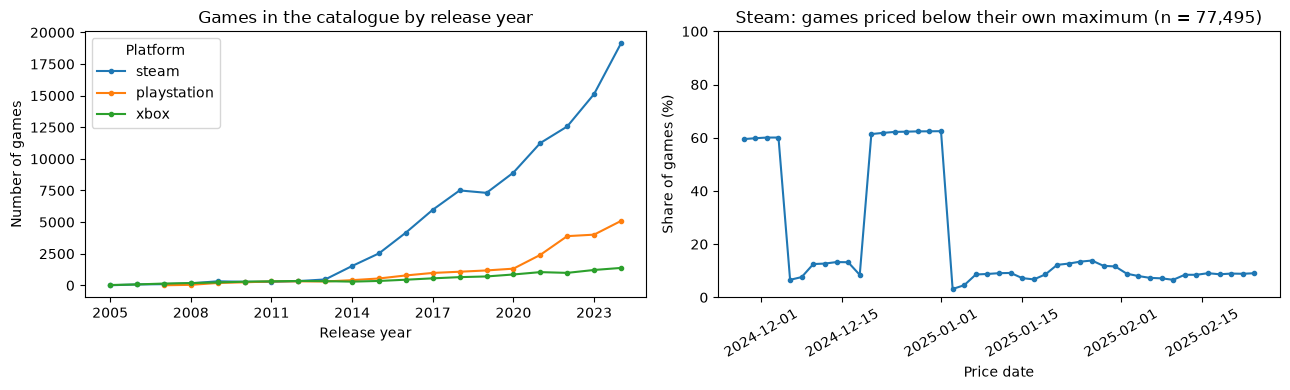

date_acquired
2024-11-28    59.5
2024-11-30    59.8
2024-12-02    60.1
2024-12-04    60.1
2024-12-20    61.4
2024-12-22    61.8
2024-12-24    62.2
2024-12-26    62.3
2024-12-28    62.4
2024-12-30    62.4
2025-01-01    62.5
Name: share_below_max_%, dtype: float64

In [15]:
# Steam is the only platform with a price time series: share of games below their own highest price on each date
steam_usd = game["steam", "prices"].pivot(index="gameid", columns="date_acquired", values="usd")
steam_usd = report_rows(steam_usd.dropna(), "Steam games with a USD price on every date", len(steam_usd))
below_max_pct = steam_usd.lt(steam_usd.max(axis=1), axis=0).mean() * 100

fig, (ax_release, ax_sale) = plt.subplots(1, 2, figsize=(13, 4))
for platform in PLATFORMS:
    per_year = game[platform, "games"]["release_date"].dt.year.value_counts().sort_index()
    ax_release.plot(per_year.loc[2005:2024], marker=".", label=platform)
ax_release.set(title="Games in the catalogue by release year", xlabel="Release year", ylabel="Number of games",
               xticks=range(2005, 2025, 3))
ax_release.legend(title="Platform")

ax_sale.plot(below_max_pct.index, below_max_pct.values, marker=".", color="tab:blue")
ax_sale.set(title=f"Steam: games priced below their own maximum (n = {len(steam_usd):,})",
            xlabel="Price date", ylabel="Share of games (%)", ylim=(0, 100))
ax_sale.tick_params(axis="x", rotation=30)
fig.tight_layout()
fig.savefig(FIG_DIR / "explore_release_years_and_steam_sales.png", dpi=150)
plt.show()
# Dates on which more than 30 % of games are below their own highest price: the sale windows
below_max_pct[below_max_pct > 30].round(1).rename("share_below_max_%")

#### Game side: observations

- **Release dates are plausible.** No date lies after the end of the collection, and at most 0.13 % fall on 1 January,
  so there is no sign of a default date. The catalogues are dominated by recent games: 68 % of Steam, 73 % of
  PlayStation and 53 % of Xbox games were released in 2020 or later. Steam alone added 19,128 games dated 2024, against
  2,528 dated 2015.
- **Price dates differ by platform.** Steam has 45 dates, one every two days, from 28 November 2024 to 24 February 2025.
  PlayStation has three dates, but 25 February holds only 1,374 rows against 30,721 on the other two days, so it is a
  partial snapshot. Xbox has two dates (22 and 24 February). **22 February 2025 is the only complete date shared by the
  three platforms**, and it is the reference day for price comparisons in sections 2.5 and 2.8.
- **Steam sales are visible in the data.** Among the 77,495 Steam games priced on every date, about 60 % sit below their
  own highest price from 28 November to 4 December and about 62 % from 20 December to 1 January, against 3 to 14 % on the
  other dates. These two windows match Steam's Autumn and Winter Sales 2024. The first one had already started when the
  collection began, so it has no "before" period in the data.

In [16]:
# Player side: players, history, purchased_games, reviews, friends, private_steamids (owner: TODO)

### 2.5 Numerical columns

TODO: distribution shape, centre and spread; plausible min/max; outliers (IQR, z-score) genuine or errors;
impossible or placeholder values.

In [17]:
# Game side: games, achievements, prices (owner: minhnguyen1210)
COMMON_DAY = pd.Timestamp("2025-02-22")  # the only date with prices for all three platforms; Steam is not on sale

usd_rows, zero_rows = [], []
for platform in PLATFORMS:
    prices = game[platform, "prices"]
    usd = prices.loc[prices["date_acquired"] == COMMON_DAY, "usd"].dropna()
    q1, q3 = usd.quantile([0.25, 0.75])
    usd_rows.append({
        "platform": platform, "games_priced": len(usd), "median": usd.median(), "mean": round(usd.mean(), 2),
        "Q1": q1, "Q3": q3, "max": usd.max(), "skewness": round(usd.skew(), 1),
        "above_Q3_plus_1.5_IQR_%": round(100 * (usd > q3 + 1.5 * (q3 - q1)).mean(), 1),
    })
    # a 0 in one currency while the same row has a positive USD price is a placeholder, not a free game
    zero_rows.append({"platform": platform, "zero_usd": int((prices["usd"] == 0).sum()),
                      **{f"zero_{c}_with_positive_usd": int(((prices[c] == 0) & (prices["usd"] > 0)).sum())
                         for c in ["eur", "gbp", "jpy", "rub"]}})
display(pd.DataFrame(usd_rows))
display(pd.DataFrame(zero_rows).set_index("platform"))

# The most expensive Steam prices: real products or errors?
steam_titles = game["steam", "games"].set_index("gameid")["title"]
top = (game["steam", "prices"].groupby("gameid")["usd"].max().nlargest(5).to_frame("max_usd")
       .join(steam_titles))
top

,platform,games_priced,median,mean,Q1,Q3,max,skewness,above_Q3_plus_1.5_IQR_%
0,steam,77985,4.99,9.09,2.99,9.99,999.98,16.8,5.9
1,playstation,24049,7.99,12.11,2.99,17.99,99.99,1.8,2.8
2,xbox,8001,14.99,17.15,7.99,19.99,109.99,1.6,8.7


,zero_usd,zero_eur_with_positive_usd,zero_gbp_with_positive_usd,zero_jpy_with_positive_usd,zero_rub_with_positive_usd
platform,,,,,
steam,0,0,45,0,25
playstation,0,0,0,0,2
xbox,0,0,0,0,0


,max_usd,title
gameid,,
2499620,999.98,The Leverage Game
2504210,999.98,The Leverage Game Business Edition
1200520,999.00,Ascent Free-Roaming VR Experience
3013840,500.00,True Love
1105450,299.99,Aartform Curvy 3D 4.0


,platform,games,median,p90,p99,max,game_with_max
0,steam,50548,18.0,54.0,152.0,10979,The Mexican Dream
1,playstation,30721,22.0,51.0,71.0,411,Train Sim World 2
2,xbox,11319,26.0,52.0,100.0,700,Halo: The Master Chief Collection


Xbox points per achievement: median 20, 796 achievements worth 0, max 1000
Xbox points per game (gamerscore): median 1000, 76% of games total exactly 1,000


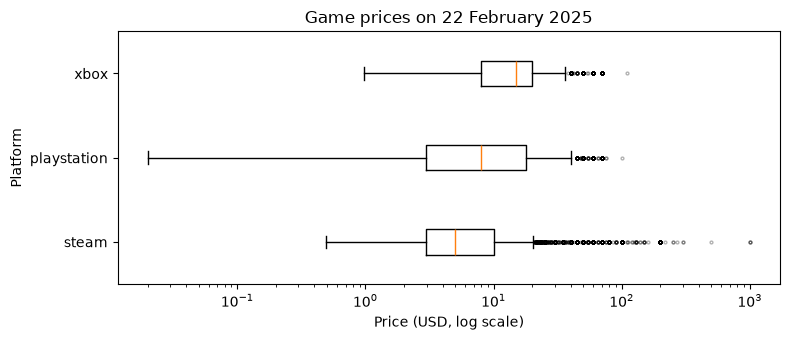

In [18]:
# Achievements per game and Xbox points
ach_rows = []
for platform in PLATFORMS:
    per_game = game[platform, "achievements"].groupby("gameid").size()
    ach_rows.append({"platform": platform, "games": len(per_game), "median": per_game.median(),
                     "p90": per_game.quantile(0.9), "p99": per_game.quantile(0.99), "max": per_game.max(),
                     "game_with_max": game[platform, "games"].set_index("gameid")["title"].get(per_game.idxmax())})
display(pd.DataFrame(ach_rows))

xbox_points = game["xbox", "achievements"]
points_per_game = xbox_points.groupby("gameid")["points"].sum()
print(f"Xbox points per achievement: median {xbox_points['points'].median():.0f}, "
      f"{(xbox_points['points'] == 0).sum():,} achievements worth 0, max {xbox_points['points'].max()}")
print(f"Xbox points per game (gamerscore): median {points_per_game.median():.0f}, "
      f"{(points_per_game == 1000).mean():.0%} of games total exactly 1,000")

# Price distribution on the common day (log scale: prices are strongly right-skewed)
fig, ax = plt.subplots(figsize=(8, 3.5))
data = [game[p, "prices"].loc[lambda d: d["date_acquired"] == COMMON_DAY, "usd"].dropna() for p in PLATFORMS]
ax.boxplot(data, orientation="horizontal", showfliers=True, flierprops={"markersize": 2, "alpha": 0.3})
ax.set_yticks(range(1, len(PLATFORMS) + 1), PLATFORMS)
ax.set_xscale("log")
ax.set(title="Game prices on 22 February 2025", xlabel="Price (USD, log scale)", ylabel="Platform")
fig.tight_layout()
fig.savefig(FIG_DIR / "explore_price_distribution.png", dpi=150)
plt.show()

#### Game side: observations

- **Prices are strongly right-skewed.** On 22 February 2025 the median price is USD 4.99 on Steam (IQR 2.99 to 9.99,
  mean 9.09, skewness 16.8), USD 7.99 on PlayStation and USD 14.99 on Xbox. The IQR rule flags 5.9 % of Steam prices
  and 8.7 % of Xbox prices as outliers, but its thresholds (about USD 20 on Steam and USD 38 on Xbox) fall on ordinary
  full-price games, so the rule is not used to remove rows; prices are analysed on a log scale or by their median.
- **Extreme values are mostly genuine.** The highest Steam prices (USD 999.98 for *The Leverage Game*, USD 999 for a VR
  experience) are real store prices of niche products and are kept. One PlayStation game costs USD 0.02 but EUR 0.26,
  which looks like an error; such cases are rare and are checked again in the analyses that use prices.
- **Zero prices are placeholders.** 45 GBP and 25 RUB prices on Steam and 2 RUB prices on PlayStation are exactly 0 while
  the same row has a positive USD price, so a 0 is treated as missing.
- **Achievements per game** have a median of 18 (Steam), 22 (PlayStation) and 26 (Xbox). Steam has extreme
  "achievement spam" games, up to 10,979 achievements for *The Mexican Dream*; the 99th percentile is 152.
- **Xbox points follow a platform rule:** 76 % of Xbox games total exactly 1,000 gamerscore points, and a single
  achievement is worth 20 points at the median.

In [19]:
# Player side: players, history, purchased_games, reviews, friends, private_steamids (owner: TODO)

### 2.6 Categorical columns

TODO: number of distinct values and most frequent ones; balance; inconsistent labels and typos;
rare categories to group.

,platform,labels,labels_ignoring_case,inconsistent_examples,labels_per_game_median,rare_labels_under_1%,top_5
0,steam,33,33,[],3.0,21,"[(Indie, 70.1), (Casual, 43.0), (Action, 41.3)..."
1,playstation,120,115,"[[Fighting, fighting], [Platformer, platformer...",1.0,87,"[(Action, 13.9), (Platformer, 11.5), (Puzzle, ..."
2,xbox,113,108,"[[Fighting, fighting], [Platformer, platformer...",1.0,73,"[(Adventure, 20.1), (Action, 15.9), (Platforme..."


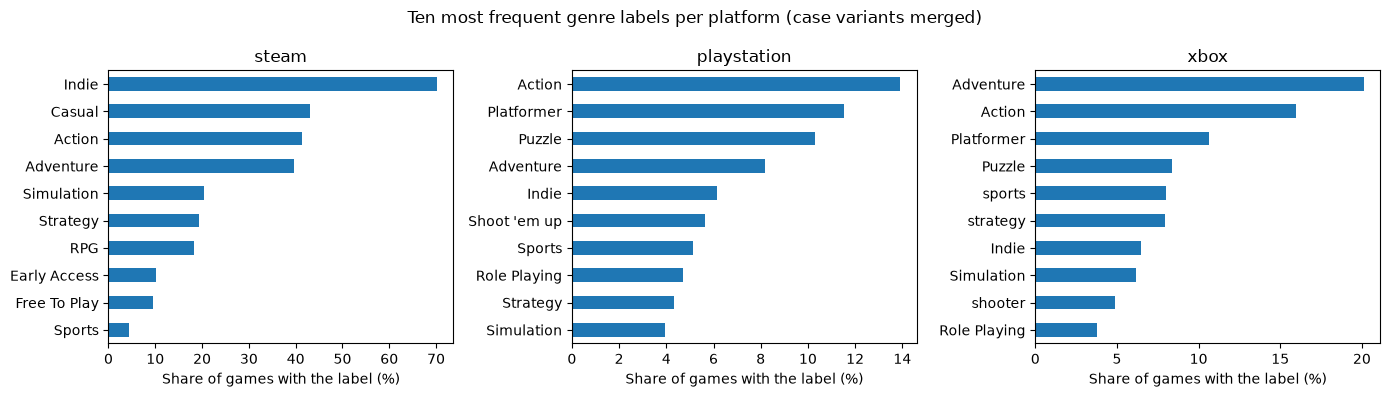

In [20]:
# Game side: games, achievements, prices (owner: minhnguyen1210)
genre_rows, genre_shares = [], {}
for platform in PLATFORMS:
    games = game[platform, "games"]
    labels = parse_list_column(games["genres"]).explode().dropna().str.strip()  # index = row of the game
    lower = labels.str.lower()
    spellings = labels.groupby(lower).unique()                     # spellings of each label, ignoring case
    inconsistent = spellings[spellings.map(len) > 1]
    canonical = lower.map(labels.groupby(lower).agg(lambda s: s.mode()[0]))  # most frequent spelling
    per_game = canonical.rename("label").reset_index().drop_duplicates()     # each label once per game
    share = per_game["label"].value_counts() / games["genres"].notna().sum() * 100  # % of games with the label
    genre_shares[platform] = share
    genre_rows.append({
        "platform": platform, "labels": labels.nunique(), "labels_ignoring_case": len(spellings),
        "inconsistent_examples": [list(v) for v in inconsistent.head(3)],
        "labels_per_game_median": parse_list_column(games["genres"]).str.len().median(),
        "rare_labels_under_1%": int((share < 1).sum()),
        "top_5": list(share.head(5).round(1).items()),
    })
display(pd.DataFrame(genre_rows))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, platform in zip(axes, PLATFORMS):
    genre_shares[platform].head(10).sort_values().plot.barh(ax=ax)
    ax.set(title=platform, xlabel="Share of games with the label (%)", ylabel="")
fig.suptitle("Ten most frequent genre labels per platform (case variants merged)")
fig.tight_layout()
fig.savefig(FIG_DIR / "explore_top_genres.png", dpi=150)
plt.show()

In [21]:
# Other categorical columns: PlayStation console and trophy grade, publishers, languages
ps_trophies = game["playstation", "achievements"]
platinum_per_game = ps_trophies.assign(is_platinum=ps_trophies["rarity"] == "Platinum").groupby("gameid")["is_platinum"].sum()
display(pd.concat({
    "PS games by console (%)": game["playstation", "games"]["platform"].value_counts(normalize=True).mul(100).round(1),
    "PS trophies by grade (%)": ps_trophies["rarity"].value_counts(normalize=True, sort=False).mul(100).round(1),
}))
print("PS games by number of Platinum trophies:", platinum_per_game.value_counts().sort_index().to_dict())

other_rows = []
for platform in PLATFORMS:
    games = game[platform, "games"]
    publishers = parse_list_column(games["publishers"]).explode().dropna()
    other_rows.append({
        "platform": platform,
        "distinct_publishers": publishers.nunique(),
        "top_3_publishers": list(publishers.value_counts().head(3).items()),
        "languages_per_game_median": parse_list_column(games["supported_languages"]).str.len().median(),
    })
pd.DataFrame(other_rows)

PS games by console (%)   PS4         61.2
                          PS5         27.7
                          PS3          6.8
                          PS Vita      4.3
PS trophies by grade (%)  Bronze      51.7
                          Silver      24.9
                          Gold        20.4
                          Platinum     3.0
Name: proportion, dtype: float64

PS games by number of Platinum trophies: {0: 5132, 1: 25589}


,platform,distinct_publishers,top_3_publishers,languages_per_game_median
0,steam,50803,"[(Big Fish Games, 511), (8floor, 268), (SEGA, ...",1.0
1,playstation,2538,"[(eastasiasoft, 1185), (Ratalaika Games, 966),...",6.0
2,xbox,2268,"[(Microsoft Studios, 386), (Electronic Arts, 2...",5.0


#### Game side: observations

- **Genre labels are not comparable across platforms.** Steam uses 33 clean store labels, a median of 3 per game, and
  some are not genres at all (*Indie* on 70 % of games, *Early Access*, *Free To Play*). PlayStation (120 labels) and Xbox
  (113) use a finer taxonomy with typically one label per game, and the same label appears in different cases
  (*Puzzle* and *puzzle*, *Fighting* and *fighting*), leaving 115 and 108 labels once case is ignored. 87 PlayStation and
  73 Xbox labels cover less than 1 % of games each.
- **Decision:** merge case variants (keep the most frequent spelling), group labels under 1 % as "Other", and compare
  genres within a platform rather than across platforms.
- **PlayStation:** 61 % of games are PS4 and 28 % PS5 versions. Trophies are 52 % Bronze, 25 % Silver, 20 % Gold and 3 %
  Platinum. No game has more than one Platinum: 25,589 games have one and 5,132 have none.
- **Publishers** form a long tail: Steam has 50,803 distinct publishers, the largest (Big Fish Games) with only 511 games.
  On PlayStation the most frequent publishers are budget porting labels (eastasiasoft 1,185 games, Ratalaika Games 966).

In [22]:
# Player side: players, history, purchased_games, reviews, friends, private_steamids (owner: TODO)

### 2.7 Missing data

TODO: count and percentage per column; whether missingness follows a pattern; why values are missing;
how each column will be handled (drop, impute, separate category).

In [23]:
# Game side: games, achievements, prices (owner: minhnguyen1210)
# Share of missing values per column (%), one column per platform; only columns with missing values
missing = pd.concat(
    {(name, platform): game[platform, name].isna().mean() * 100 for platform, name in GAME_SIDE_TABLES},
    names=["table", "platform", "column"],
).unstack("platform")[PLATFORMS]
display(missing[missing.sum(axis=1) > 0].round(1))

# Patterns behind the gaps
steam_games = game["steam", "games"]
no_metadata = steam_games["genres"].isna()
is_playtest = steam_games["title"].str.contains("playtest", case=False, na=False)
print(f"Steam games without genres: {no_metadata.sum():,}; "
      f"of these {(no_metadata & steam_games['developers'].isna()).mean() / no_metadata.mean():.0%} also lack developers "
      f"and {(no_metadata & is_playtest).sum() / no_metadata.sum():.0%} are playtests")

price_gaps = []
for platform in PLATFORMS:
    prices = game[platform, "prices"]
    never_usd = prices.groupby("gameid")["usd"].count() == 0
    price_gaps.append({
        "platform": platform,
        "games_never_priced_in_usd": int(never_usd.sum()),
        "games_never_priced_%": round(100 * never_usd.mean(), 1),
        "rows_with_usd_but_no_eur_%": round(100 * (prices["usd"].notna() & prices["eur"].isna()).mean(), 1),
    })
pd.DataFrame(price_gaps)

platform                          steam  playstation   xbox
table        column                                        
achievements description            8.9          0.0    0.0
             points                 NaN          NaN    0.3
             title                  0.2          0.0    0.0
games        developers             5.7          0.1    5.5
             genres                 5.6          0.6    5.8
             publishers             6.0          0.0    5.2
             supported_languages    5.6         54.2   63.4
             title                  0.0          0.0    0.0
prices       eur                   38.6         24.8   32.6
             gbp                   20.6         22.6   30.2
             jpy                   20.8         57.0  100.0
             rub                   22.8         82.6   36.5
             usd                   20.6         21.6   29.3

Steam games without genres: 5,549; of these 98% also lack developers and 95% are playtests


,platform,games_never_priced_in_usd,games_never_priced_%,rows_with_usd_but_no_eur_%
0,steam,20049,20.4,18.0
1,playstation,6664,21.7,4.7
2,xbox,3317,29.3,3.5


#### Game side: observations

- **Game metadata is missing together.** The 5,549 Steam games without genres almost always lack developers as well
  (98 %), and 95 % of them are playtests, which have no store page. The gap is therefore not random and concerns test
  builds rather than real games.
- **Missing USD prices mean "not for sale"**: 20,049 Steam games (20.4 %), 6,664 PlayStation games and 3,317 Xbox games
  never have a USD price in any snapshot (free games or games not sold in the US store).
- **Other currencies are less complete.** 18 % of Steam rows have a USD price but no EUR price; Xbox has no JPY price at
  all, and 83 % of PlayStation RUB prices are missing.
- `supported_languages` is missing for 54 % of PlayStation and 63 % of Xbox games; `achievements.description` is missing
  for 8.9 % of Steam achievements.

| Column | Missing | Handling |
| --- | --- | --- |
| `games.genres`, `developers`, `publishers` | 5 to 6 % (Steam, Xbox) | keep the rows; "Unknown" when a genre is needed; playtests excluded from game-level analyses |
| `games.supported_languages` | 54 to 63 % on consoles | descriptive use only, never as a model feature on consoles |
| `prices.usd` | 21 to 29 % of rows | drop the row in price analyses (the game is not for sale) |
| `prices.eur`, `gbp`, `jpy`, `rub` | 21 to 100 % | not used in the questions; summaries only |
| `achievements.points` (Xbox) | 0.3 % | keep; ignored in sums |
| `achievements.description` | 8.9 % (Steam) | not used |

In [24]:
# Player side: players, history, purchased_games, reviews, friends, private_steamids (owner: TODO)

### 2.8 Relationships

TODO: correlations between numerical variables; cross-tabulations and grouped statistics for important
combinations; surprising relationships.

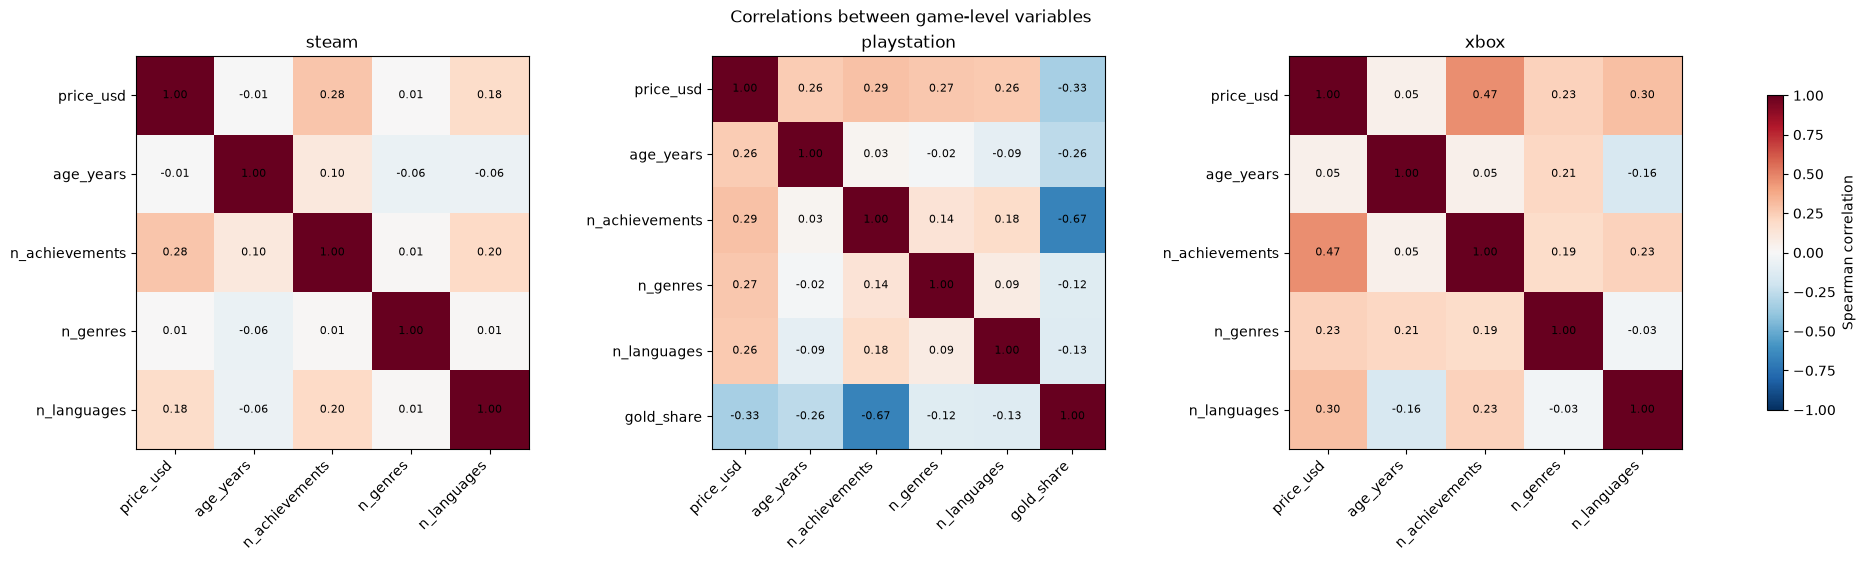

In [25]:
# Game side: games, achievements, prices (owner: minhnguyen1210)
def game_level_features(platform):
    """One row per game: price on COMMON_DAY, age, number of achievements, genres and languages."""
    games = game[platform, "games"].set_index("gameid")
    prices = game[platform, "prices"]
    features = pd.DataFrame({
        "price_usd": prices[prices["date_acquired"] == COMMON_DAY].set_index("gameid")["usd"],
        "age_years": (COMMON_DAY - games["release_date"]).dt.days / 365.25,
        "n_achievements": game[platform, "achievements"].groupby("gameid").size(),
        "n_genres": parse_list_column(games["genres"]).str.len(),
        "n_languages": parse_list_column(games["supported_languages"]).str.len(),
    }).reindex(games.index)  # keep only games present in the games table
    if platform == "playstation":
        trophies = game[platform, "achievements"]
        features["gold_share"] = (trophies["rarity"] == "Gold").groupby(trophies["gameid"]).mean()
    return features

features = {platform: game_level_features(platform) for platform in PLATFORMS}

# Spearman correlation: rank-based, so robust to the strong skew of prices and achievement counts
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5), layout="constrained")
for ax, platform in zip(axes, PLATFORMS):
    corr = features[platform].corr(method="spearman")
    image = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
    ax.set_yticks(range(len(corr)), corr.columns)
    for (i, j), value in np.ndenumerate(corr.values):
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8)
    ax.set_title(platform)
fig.colorbar(image, ax=axes, shrink=0.8, label="Spearman correlation")
fig.suptitle("Correlations between game-level variables")
fig.savefig(FIG_DIR / "explore_game_correlations.png", dpi=150)
plt.show()

In [26]:
# Grouped statistics: median price by game age, and by PlayStation console
age_bins, age_labels = [0, 1, 3, 5, 10, 100], ["< 1", "1-3", "3-5", "5-10", "> 10"]
by_age = pd.concat({
    platform: features[platform].groupby(pd.cut(features[platform]["age_years"], age_bins, labels=age_labels),
                                         observed=True)["price_usd"].median()
    for platform in PLATFORMS
}, axis=1)
display(by_age.rename_axis("age (years)").round(2))

ps = features["playstation"].join(game["playstation", "games"].set_index("gameid")["platform"])
ps.groupby("platform", observed=True).agg(games=("price_usd", "size"), median_price=("price_usd", "median"),
                                          median_trophies=("n_achievements", "median"), median_gold_share=("gold_share", "median"))

,steam,playstation,xbox
age (years),,,
< 1,5.50,4.99,11.99
1-3,4.99,6.99,14.99
3-5,4.99,8.99,14.99
5-10,4.99,12.99,14.99
> 10,9.99,12.99,14.99


,games,median_price,median_trophies,median_gold_share
platform,,,,
PS Vita,995,9.99,21.0,0.147059
PS3,1571,14.99,35.0,0.076923
PS4,14163,7.99,21.0,0.230769
PS5,6422,6.99,22.0,0.307692


#### Game side: observations

Spearman correlations are computed per platform on one row per game (price on 22 February 2025).

- **Price rises with the number of achievements** on every platform (Spearman 0.28 on Steam, 0.29 on PlayStation, 0.47
  on Xbox): larger games define more achievements and cost more.
- **Age and price relate differently across platforms.** On Steam the median price stays near USD 5 for games up to ten
  years old (USD 9.99 beyond), and age and price are uncorrelated overall (-0.01). On PlayStation recent games are cheaper (median USD 4.99 for games under one year,
  USD 12.99 for games older than five years; Spearman 0.26).
- **Surprising PlayStation pattern:** the share of Gold trophies falls sharply as the number of trophies grows (Spearman
  -0.67) and is lower for more expensive games (-0.33). PS5 games are the cheapest (median USD 6.99) and have the highest
  Gold share (31 %), PS3 games the most expensive (USD 14.99) with the lowest (8 %). Small, cheap games award many Gold
  trophies, so Gold does not necessarily mean "hard"; this is a pattern worth testing as a question.

In [27]:
# Player side: players, history, purchased_games, reviews, friends, private_steamids (owner: TODO)

## 3 Exploration summary

Game-side points come from sections 2.1 to 2.8 (`games`, `achievements`, `prices`); player-side points are added by
the owner of the player-side tables.

### 3.1 Key observations (3–5)

1. **The catalogues are dominated by recent, cheap games.** 68 % of Steam, 73 % of PlayStation and 53 % of Xbox games
   were released in 2020 or later, and the median price on 22 February 2025 is USD 4.99 on Steam, 7.99 on PlayStation
   and 14.99 on Xbox. Prices are strongly right-skewed (skewness 16.8 on Steam), so medians and log scales describe them
   better than means (sections 2.4, 2.5).
2. **Steam's seasonal sales are visible directly in the price data.** About 60 % (28 November to 4 December 2024) and
   62 % (20 December 2024 to 1 January 2025) of the games priced on every date sit below their own highest price,
   against 3 to 14 % on the other dates. Only the winter sale has a complete before, during and after period (section 2.4).
3. **PlayStation trophy grades do not simply reflect game size or price.** The share of Gold trophies falls as the
   number of trophies grows (Spearman -0.67) and as the price rises (-0.33); PS5 games are the cheapest (median USD 6.99)
   and award the most Gold trophies (31 % at the median). This is the most surprising game-side pattern (section 2.8).
4. TODO (player side, CaoThien1402).

### 3.2 Serious data quality issues

- **Incomplete console game tables:** 7,570 PlayStation game ids (24.6 %) and 830 Xbox ids appear in `prices` and
  `achievements` but not in `games`, so 26 % of PlayStation trophies have no genre or release date (section 2.3).
- **Inconsistent genre labels:** each platform uses its own taxonomy, PlayStation and Xbox store the same label in
  different cases (*Puzzle* and *puzzle*), and some Steam labels are store tags rather than genres (*Indie*, *Early
  Access*, *Free To Play*) (section 2.6).
- **Placeholder and implausible prices:** 72 prices of exactly 0 (GBP and RUB) sit on rows with a positive USD price,
  and one PlayStation game costs USD 0.02 (section 2.5).
- **Uneven price snapshots:** the PlayStation snapshot of 25 February 2025 holds 1,374 rows instead of 30,721, and the
  consoles have only two complete price dates (section 2.4).
- **Test builds in the Steam catalogue:** 5,294 playtests have no metadata and never a price (sections 2.2, 2.7).
- TODO (player side, CaoThien1402): confirm in section 2 the player-side issues listed in section 1.4 (limitations 3
  to 5) and add any new ones.

### 3.3 Preprocessing plan

| Step | Tables | Rule | Output in `data/processed/` | Used by |
| --- | --- | --- | --- | --- |
| Load | `games`, `achievements`, `prices` | `load_game_table` with the settings of section 2.1 | – | every analysis |
| Remove test builds | Steam `games` | exclude titles containing "Playtest" from game-level analyses | – | game-level analyses |
| Normalise genres | `games` | parse the lists, merge case variants into the most frequent spelling, group labels used by fewer than 1 % of games as "Other", keep missing as "Unknown" | – | analyses by genre |
| Clean prices | `prices` | drop rows without a USD price (not for sale); treat a 0 in any currency as missing; compare platforms on 22 February 2025 | – | price analyses |
| Steam price panel | Steam `prices` | keep the 77,495 games with a USD price on all 45 dates; one row per game, one column per date | `steam_prices_wide.parquet` | analyses of Steam sales |
| Attach game attributes | `prices`, `achievements` -> `games` | left join on `gameid`; report how many rows get no attribute | – | analyses needing genre or release date |
| TODO (player side, CaoThien1402) | | | | |

### 3.4 Patterns that could lead to questions

- **Discount depth and price recovery around Steam sales** (section 2.4): how deep the discounts go, for which games, and
  whether prices return to, or rise above, their pre-sale level.
- **Trophy grades versus real difficulty on PlayStation** (section 2.8): the Gold share depends strongly on game size and
  price, so the grade may not mean "hard"; unlock rates from `history` can test this.
- **Platform-specific pricing** (sections 2.5, 2.8): Xbox prices are higher and tied to the number of achievements
  (Spearman 0.47), while recent PlayStation games are cheaper than older ones.
- TODO (player side, CaoThien1402).